# 1. Data, SQL and EDA

**The business:** a grocery retailer with 2,469 loyalty-card households, one year of transactions (2017),
and 27 marketing campaigns. The big ones are four waves of personalised coupon booklets ("Type A").

**This notebook:** how the raw tables become a clean warehouse, what had to be cleaned, and six questions a
CRM manager would ask before trusting any model. Every query lives in `sql/` so it can be read without Python.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

from couponroi import config
from couponroi.warehouse import connect

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()  # read-only DuckDB warehouse built by `couponroi build`
R = lambda name: json.loads((config.RESULTS_DIR / f"{name}.json").read_text())  # noqa: E731
fig = lambda name, width=900: display(Image(filename=str(config.FIG_DIR / f"{name}.png"), width=width))  # noqa: E731
sql = lambda path: (config.SQL_DIR / path).read_text()  # noqa: E731

## The warehouse

8 raw tables in, a small star schema out. The main table for analysis is `hh_week`: one row per household per week, dense (weeks with no shopping are zeros, which matters for averages).

In [2]:
tables = ["raw_transactions", "raw_promotions", "raw_products", "raw_campaigns", "raw_coupons",
          "fct_transactions", "dim_household", "dim_week", "dim_campaign", "fct_campaign_exposure", "hh_week"]
pd.DataFrame({"table": tables, "rows": [con.execute(f"SELECT count(*) FROM {t}").fetchone()[0] for t in tables]})

,table,rows
0,raw_transactions,1469307
1,raw_promotions,20940529
2,raw_products,92331
3,raw_campaigns,6589
4,raw_coupons,116204
5,fct_transactions,1469307
6,dim_household,2469
7,dim_week,53
8,dim_campaign,27
9,fct_campaign_exposure,6589


## Data checks that run on every build

These are dbt-style tests in `src/couponroi/warehouse.py`. The build fails if any of them fail.

In [3]:
pd.DataFrame(R('data_quality')['checks'])

,check,value,passed
0,fct_transactions keeps every raw line,"{'raw': 1469307, 'fct': 1469307}",True
1,panel spend reconciles to raw sales,"{'raw': 4596039.58, 'panel': 4596039.58}",True
2,panel is dense (households x weeks),"{'households': 2469, 'weeks': 53, 'rows': 130857}",True
3,panel has one row per household-week,0,True
4,weeks 2-52 have exactly 7 local days,0,True
5,every exposed household shopped,0,True
6,redemptions fall inside their campaign window,0,True
7,only exposed households redeem,0,True
8,share of households with demographics,0.324,True


## Things that needed cleaning

* **Time zones.** Timestamps are stored in UTC, but retailer weeks flip at midnight US Eastern. A fixed
  "minus 5 hours" shift was wrong for 34 weeks because of daylight saving, so local time uses a proper
  `America/New_York` conversion. The check above ("weeks 2-52 have exactly 7 local days") is what caught it.
* **Partial weeks.** Week 1 is a single Sunday, and week 53 lost Christmas Day. Week 1 is never used as a baseline.
* **Fuel.** Fuel quantities are in odd units and fuel prices move spend for reasons coupons can't touch, so the
  main outcome is spend excluding fuel.
* **Orphan products.** About 4.8K transaction lines point at products missing from the product table. They get an
  UNKNOWN placeholder instead of being silently dropped by an inner join.
* **Demographics.** Only 801 of 2,469 households have them, and they're not a random subset (question 6).

In [4]:
con.execute("""
    SELECT week, week_start, week_end, days_observed, baskets, active_households, round(sales) AS sales
    FROM dim_week WHERE week IN (1, 2, 52, 53) ORDER BY week
""").df()

,week,week_start,week_end,days_observed,baskets,active_households,sales
0,1,2016-12-26,2017-01-01,1,382,315,"10,477.000"
1,2,2017-01-02,2017-01-08,7,2919,1318,"93,370.000"
2,52,2017-12-18,2017-12-24,7,3362,1428,"113,193.000"
3,53,2017-12-25,2017-12-31,6,2546,1244,"80,829.000"


## Q1. Who is growing and who is shrinking?

In [5]:
seg = con.execute(sql("analysis/growth_segments.sql")).df()
seg.segment.value_counts()

segment
stable       856
growing      805
declining    725
new           79
inactive       4
Name: count, dtype: int64

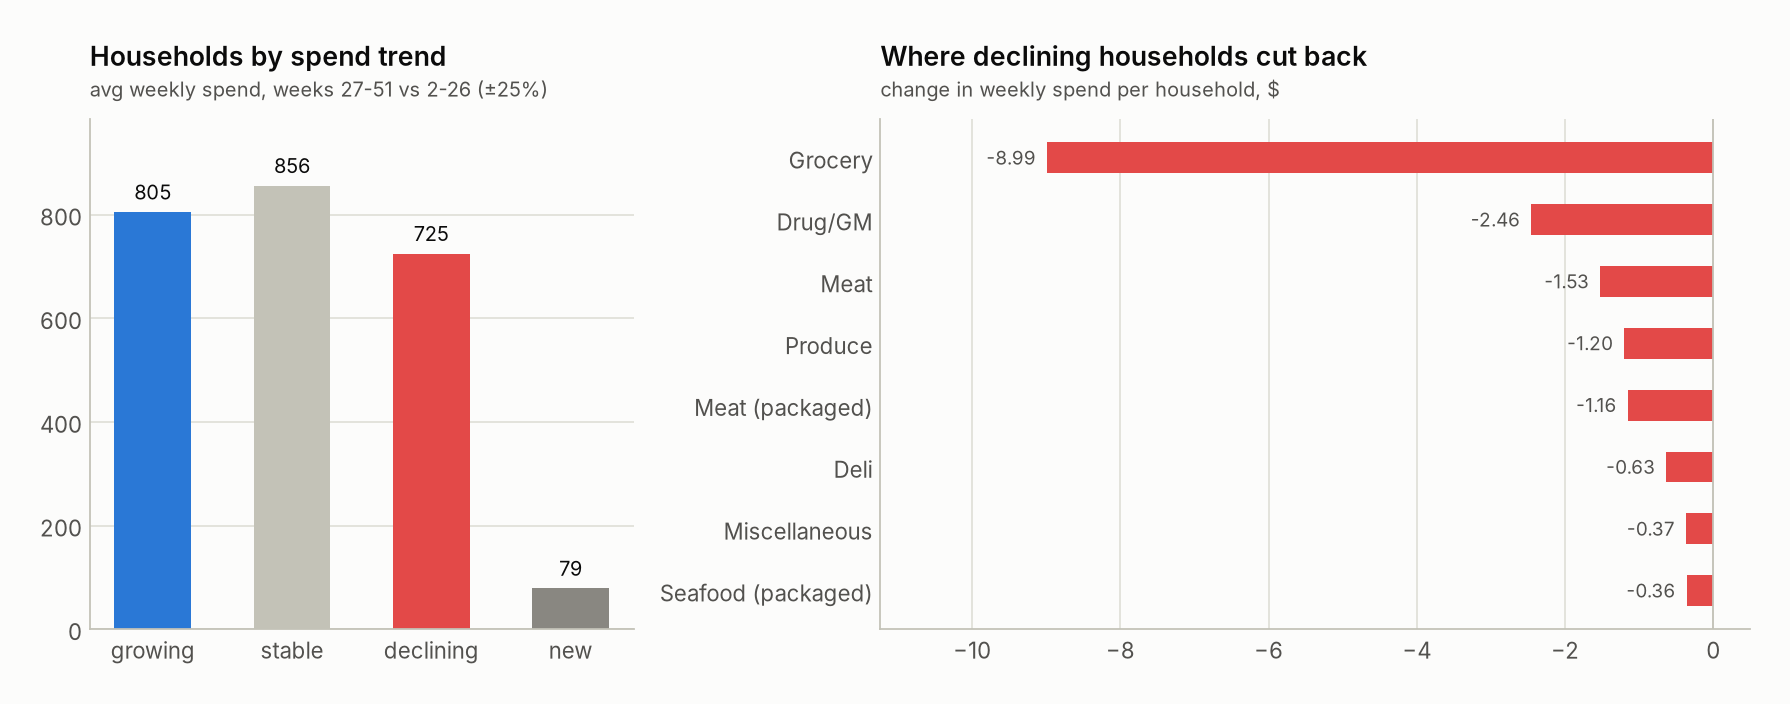

805 households grew their weekly spend by 25%+ in the second half of the year and 725 cut it by 25%+; decliners pulled back most in Grocery (-8.99 $/week per household).

In [6]:
fig('eda_1_growth_segments'); display(Markdown(R('eda')['growth_segments']['sentence']))

## Q2. Do households stick around?

In [7]:
ret = con.execute(sql("analysis/cohort_retention.sql")).df()
ret.pivot(index="cohort_block", columns="blocks_since_first", values="retention").head(4).round(2)

blocks_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_block,,,,,,,,,,,,,
0,1.000,0.910,0.890,0.890,0.890,0.890,0.900,0.890,0.880,0.870,0.880,0.890,0.880
1,1.000,0.710,0.710,0.710,0.710,0.720,0.730,0.660,0.680,0.710,0.690,0.720,NaN
2,1.000,0.510,0.640,0.620,0.580,0.580,0.560,0.590,0.650,0.720,0.660,NaN,NaN
3,1.000,0.610,0.570,0.730,0.730,0.670,0.660,0.640,0.600,0.560,NaN,NaN,NaN


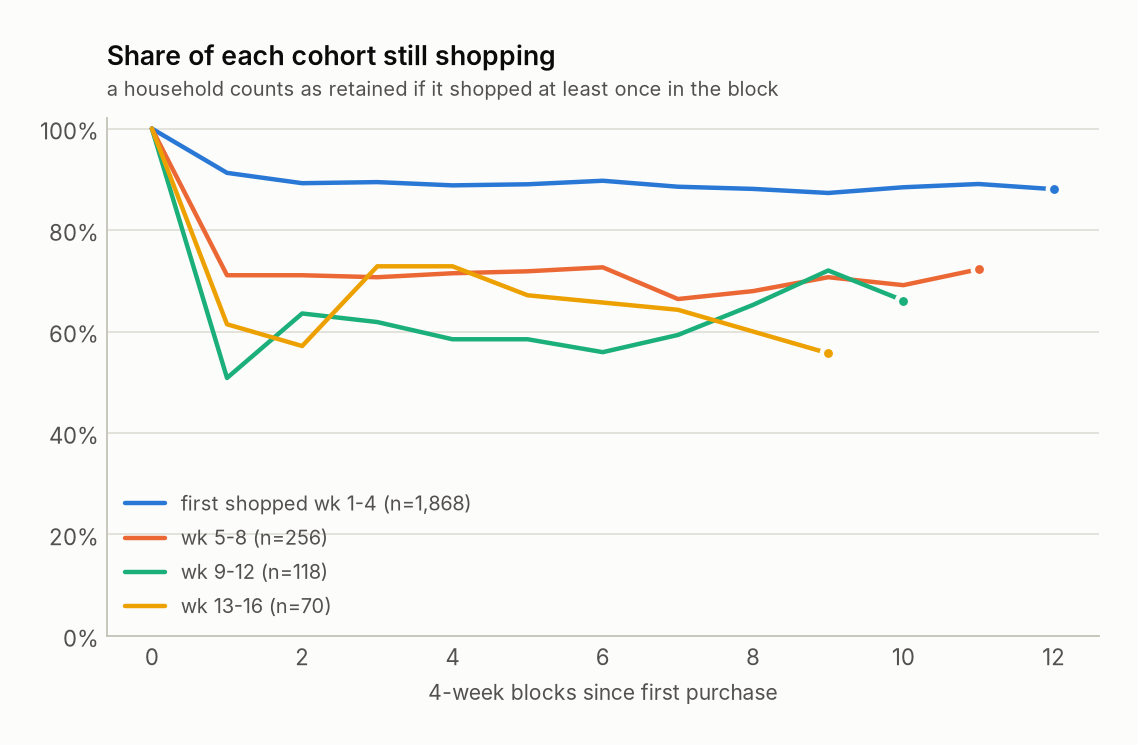

Of households that first shopped in weeks 1-4, 90% still shopped six 4-week blocks later and 88% in the final block, so outright churn is rare in this panel; the real risk is households quietly spending less.

In [8]:
fig('eda_2_cohort_retention', 700); display(Markdown(R('eda')['cohort_retention']['sentence']))

## Q3. How concentrated is revenue? (window functions + NTILE)

In [9]:
print(sql('analysis/revenue_concentration.sql'))

-- How concentrated is revenue? Households ranked by spend, cumulative share via
-- window functions, plus a 10-way NTILE for the decile table.

WITH spend AS (
    SELECT household_id, total_spend_ex_fuel AS spend
    FROM dim_household
),
ranked AS (
    SELECT
        household_id,
        spend,
        row_number() OVER (ORDER BY spend DESC) AS rank_desc,
        count(*) OVER () AS n_households,
        sum(spend) OVER (ORDER BY spend DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum_spend,
        sum(spend) OVER () AS total_spend,
        ntile(10) OVER (ORDER BY spend DESC) AS decile
    FROM spend
)
SELECT
    household_id,
    spend,
    decile,
    rank_desc / n_households AS household_share,
    cum_spend / total_spend AS cum_spend_share
FROM ranked
ORDER BY rank_desc;



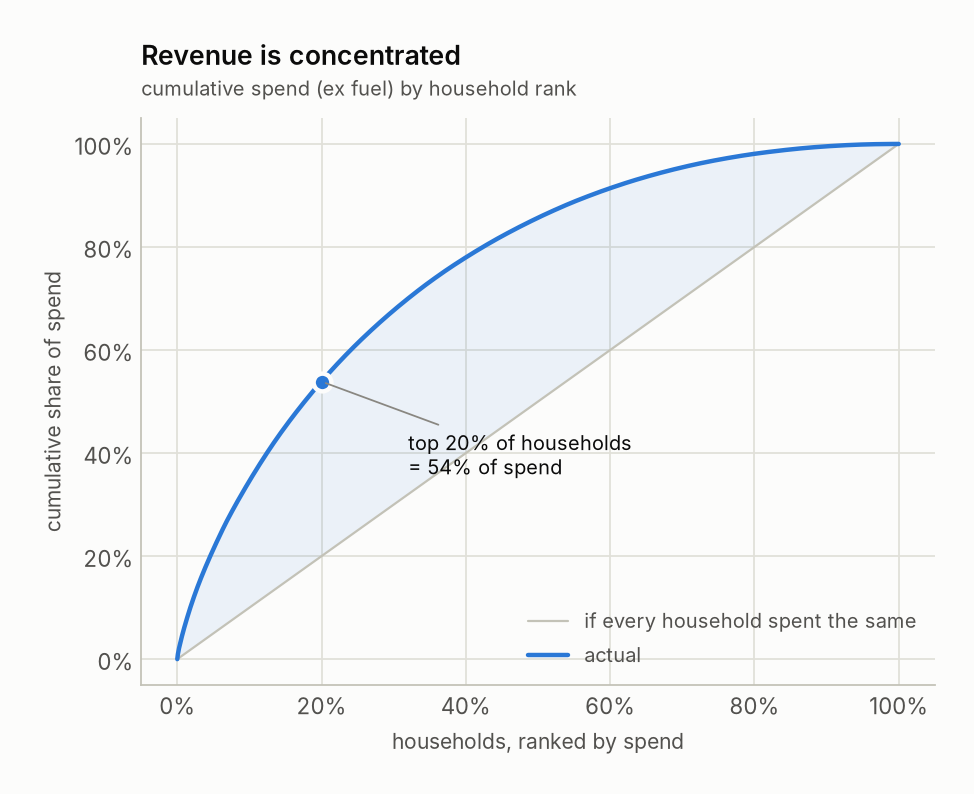

The top 20% of households bring in 54% of spend (top 10%: 35%).

In [10]:
fig('eda_3_revenue_concentration', 600); display(Markdown(R('eda')['revenue_concentration']['sentence']))

## Q4. Who gets the coupon booklets?

This is the question everything else depends on. If recipients were picked at random, comparing them to
non-recipients would measure the booklet. They weren't.

In [11]:
con.execute(sql('analysis/targeting_bias.sql')).df()

,campaign_id,recipient,households,avg_pre_weekly_spend,median_pre_weekly_spend
0,8,False,1111,21.932,12.506
1,8,True,1063,52.683,42.704
2,13,False,1158,20.789,12.651
3,13,True,1063,53.260,43.430
4,18,False,1095,20.636,12.062
5,18,True,1115,51.284,41.645
6,27,False,1684,37.829,24.715
7,27,True,344,52.737,44.892


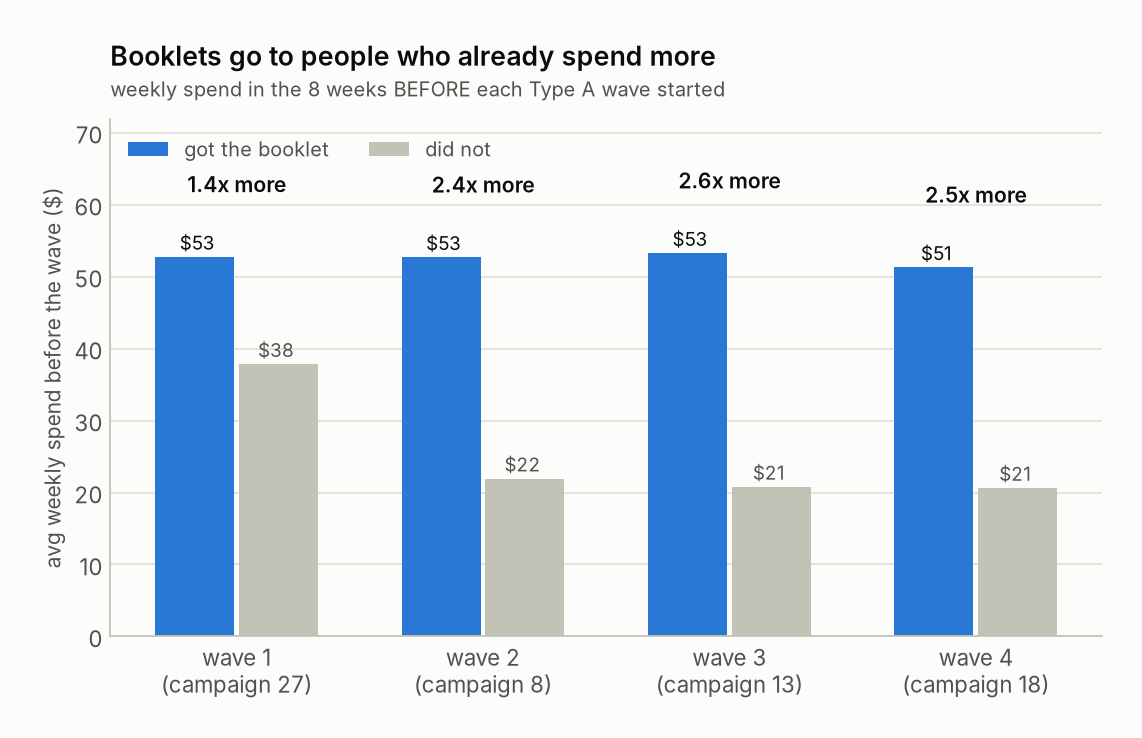

Before any booklet arrived, recipients already spent 1.4-2.6x more per week than non-recipients, so any naive 'recipients spend more' comparison is mostly targeting bias.

In [12]:
fig('eda_4_targeting_bias', 760); display(Markdown(R('eda')['targeting_bias']['sentence']))

## Q5. How many people actually redeem?

In [13]:
con.execute(sql('analysis/redemption_by_type.sql')).df()

,campaign_type,campaigns,households_targeted,redeeming_households,redemptions,household_redemption_rate,redemptions_per_100_targeted
0,Type A,4,"3,647.000",604.000,"1,718.000",0.166,47.107
1,Type B,17,"2,368.000",154.000,323.000,0.065,13.640
2,Type C,6,574.000,34.000,61.000,0.059,10.627


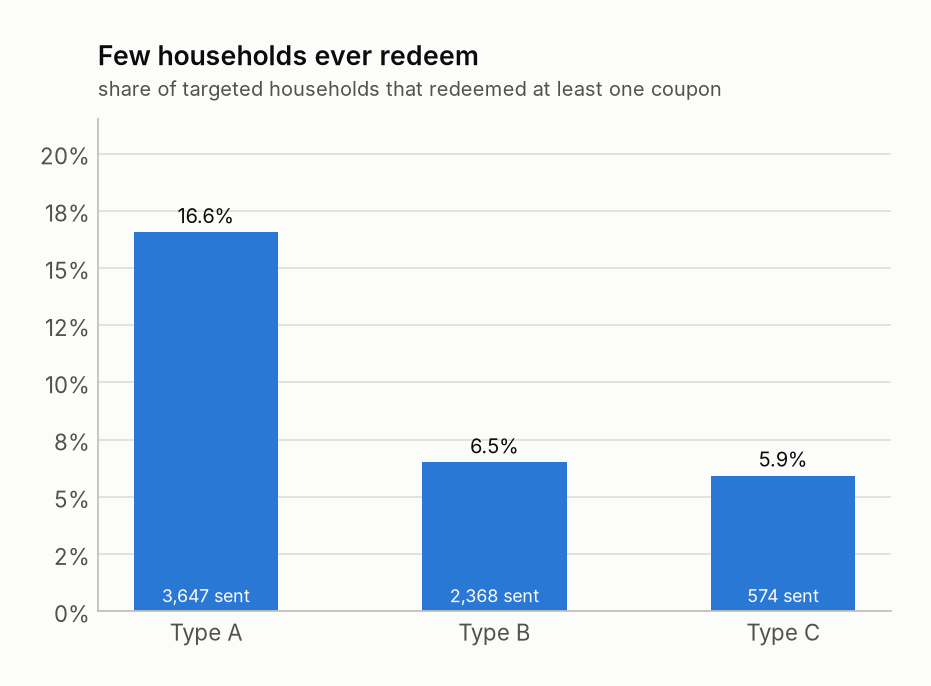

Only 17% of Type A recipients redeemed anything (Type B: 7%), and the top 10% of redeemers made 36% of all redemptions.

In [14]:
fig('eda_5_redemption', 560); display(Markdown(R('eda')['redemption']['sentence']))

## Q6. Can we trust the demographics?

In [15]:
con.execute(sql('analysis/demographics_coverage.sql')).df()

,has_demographics,households,median_weekly_spend,avg_active_weeks,avg_campaigns_received,share_got_type_a,share_of_revenue
0,True,801,45.816,40.829,4.788,0.923,0.566
1,False,1668,13.020,22.164,1.651,0.450,0.434


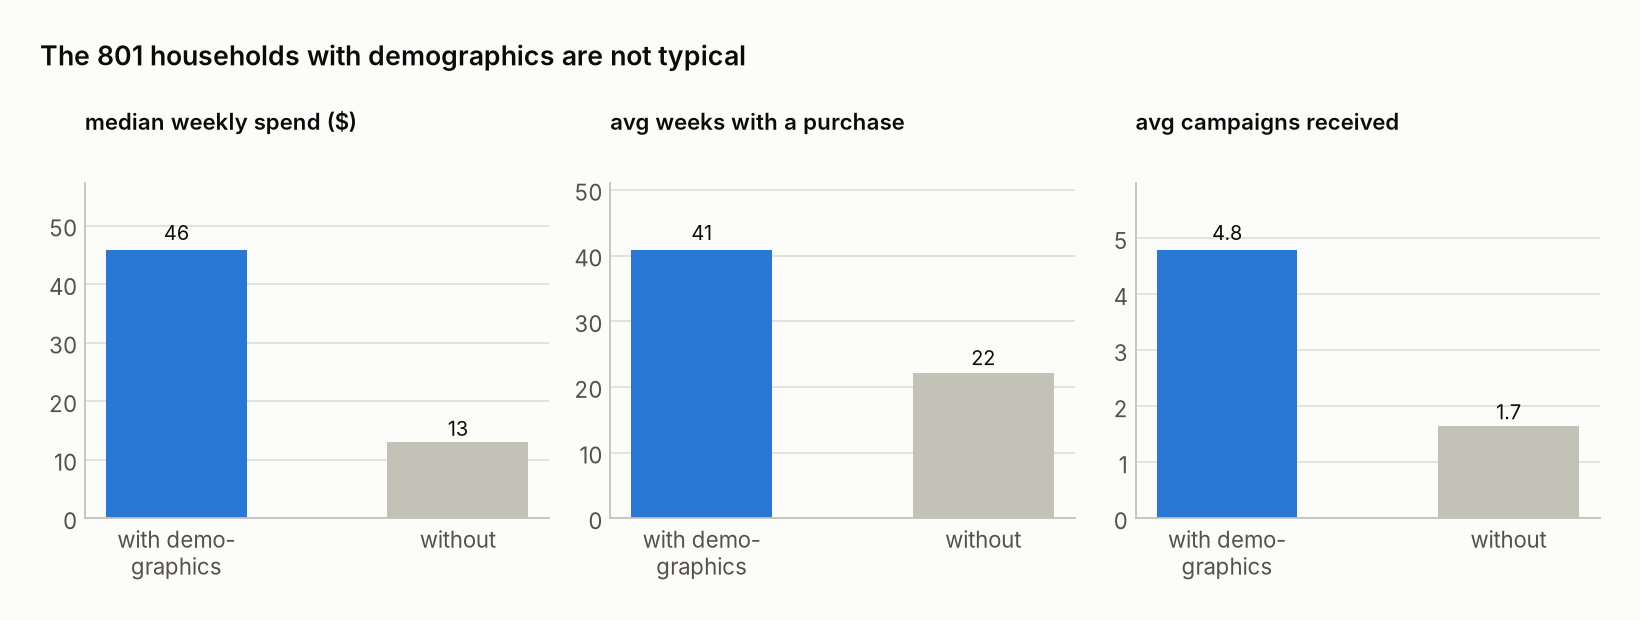

The 801 households with demographics (32% of the panel) bring 57% of revenue and have 3.5x the median weekly spend, so demographic findings describe heavy shoppers, not everyone.

In [16]:
fig('eda_6_demographics_coverage'); display(Markdown(R('eda')['demographics_coverage']['sentence']))

## What this sets up

* Booklets went to heavier shoppers, so the impact analysis has to compare recipients with look-alikes
  (notebook 2), not with everyone else.
* Outright churn is rare. The useful risk signal is a *regular* shopper going quiet (notebook 3).
* Demographics describe heavy shoppers only, so the models use behaviour, not demographics.